In [1]:
# Core scientific computing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import random
import os
import sys

# PyTorch and ML libraries
import torch
os.environ['CUDA_VISIBLE_DEVICES'] = 'MIG-f80e9374-504a-571b-bac0-6fb00750db4c'
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score

# Genomics libraries
import pybedtools
import pyfaidx
import pyBigWig

# Tangermeme for sequence manipulation and marginalization
from tangermeme.utils import one_hot_encode, random_one_hot, characters
from tangermeme.ersatz import substitute, dinucleotide_shuffle, multisubstitute
from tangermeme.predict import predict
from tangermeme.plot import plot_logo
from tangermeme.marginalize import marginalize
from tangermeme.io import extract_loci
from tangermeme.deep_lift_shap import deep_lift_shap
from tangermeme.ism import saturation_mutagenesis

# Set random seeds for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# Configure matplotlib for publication-quality plots
plt.style.use('default')
import matplotlib
matplotlib.rcParams.update({
    'font.size': 12,
    'font.family': 'DejaVu Sans',
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.format': 'pdf',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# Display PyTorch and CUDA info
print(f"PyTorch version: {torch.__version__}")
if torch.cuda.is_available():
    print(f"CUDA version: {torch.version.cuda}")
    print(f"Number of GPUs: {torch.cuda.device_count()}")
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
else:
    print("CUDA not available, using CPU")
import importlib
import helpers_4

importlib.reload(helpers_4)

from helpers_4 import *
from helpers_3 import merge_bed_files_and_label


/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/norns/cfg.py:9: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Using device: cuda
PyTorch version: 2.7.1+cu118
CUDA version: 11.8
Number of GPUs: 1
GPU 0: NVIDIA A100 80GB PCIe MIG 2g.20gb


In [2]:
hg38 = "/oak/stanford/groups/akundaje/jmschr/common/hg38/hg38.fa"

data_dir = "/oak/stanford/groups/akundaje/vir/tfatlas/processed_data/"

oct4_esc = "ENCSR000BMU"
ap1_fibroblast = "ENCSR124AIG"

peaks_file = "peaks_inliers.bed.gz"
background_peaks = "gc_neg_only.bed.gz"

esc_peaks_file = os.path.join(data_dir, oct4_esc, peaks_file)
fibroblast_peaks_file = os.path.join(data_dir, ap1_fibroblast, peaks_file)

esc_peaks_file = os.path.join("/users/kobbad/feat_leakage/data/bed_files/fibro_ipsc", "ENCSR000BMU_peaks_inliers.bed.gz")
fibroblast_peaks_file = os.path.join("/users/kobbad/feat_leakage/data/bed_files/fibro_ipsc", "ENCSR124AIG_peaks_inliers.bed.gz")

esc_peaks = pybedtools.BedTool(os.path.join(data_dir, oct4_esc, peaks_file))
fibroblast_peaks = pybedtools.BedTool(os.path.join(data_dir, ap1_fibroblast, peaks_file))

esc_background = pybedtools.BedTool(os.path.join(data_dir, oct4_esc, background_peaks)).to_dataframe()
fibroblast_background = pybedtools.BedTool(os.path.join(data_dir, ap1_fibroblast, background_peaks)).to_dataframe()
fibro_ipsc_peaks, labels = merge_bed_files_and_label(fibroblast_peaks_file, esc_peaks_file, peak_size=300)
fibro_ipsc_peaks.to_csv("labeled_peaks.bed", sep="\t", header=False, index=False)

# intersect fibroblast_background and esc_background using pybedtools
esc_background = pybedtools.BedTool(os.path.join(data_dir, oct4_esc, background_peaks))
fibroblast_background = pybedtools.BedTool(os.path.join(data_dir, ap1_fibroblast, background_peaks))

active_peaks = pybedtools.BedTool("labeled_peaks.bed")

# use window to get esc_background that are 1Kb away from active_peaks
esc_background_window = esc_background.window(active_peaks, w=1000, v=True).to_dataframe()

# same for fibroblast
fibroblast_background_window = fibroblast_background.window(active_peaks, w=1000, v=True).to_dataframe()
# concatenate the background peaks
background = pd.concat([esc_background.to_dataframe(), fibroblast_background.to_dataframe()])
background["summit"] = (background.start + background.end) // 2

# only keep columns chrom, start, end, summit
background = background[["chrom", "start", "end", "summit"]]
background_labels = np.zeros((background.shape[0], 2))

In [3]:
labels.shape, fibro_ipsc_peaks.shape, background.shape, background_labels.shape

((40931, 2), (40931, 4), (166944, 4), (166944, 2))

In [4]:
# test_rows = fibro_ipsc_peaks['chrom'] == "chr16"
# fibro_ipsc_peaks_test = fibro_ipsc_peaks[test_rows]
# fibro_ipsc_peaks = fibro_ipsc_peaks[~test_rows]

# labels_test = labels[test_rows]
# labels = labels[~test_rows]

In [5]:
type(labels), type(background_labels)

(numpy.ndarray, numpy.ndarray)

In [6]:
## prepare data

relative_proportion = 0.2
test_split = 0.2
val_split = 0.2

background_sample = background.sample(n=int(fibro_ipsc_peaks.shape[0] * relative_proportion))

all_regions = pd.concat([fibro_ipsc_peaks, background_sample])
all_labels = np.concatenate([labels, np.zeros((background_sample.shape[0], 2))])

loci, keep_mask = extract_loci(all_regions, hg38, in_window=300, return_filtered=True, verbose=True)

all_labels = all_labels[keep_mask]
loci = torch.tensor(loci, dtype=torch.float32)
all_labels = torch.tensor(all_labels, dtype=torch.float32)

keep_mask = loci.sum(axis=1).sum(axis=1) == loci.shape[2]
loci = loci[keep_mask]
all_labels = all_labels[keep_mask]

X_train, X_test, y_train, y_test = train_test_split(loci, all_labels, test_size=test_split, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=val_split, random_state=42)

Loading Loci: 100%|██████████| 49117/49117 [00:03<00:00, 13890.75it/s]
/tmp/ipykernel_1647563/671930195.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loci = torch.tensor(loci, dtype=torch.float32)


In [7]:
background_loci = background.sample(n=1000)
background_loci,_ = extract_loci(background_loci, hg38, in_window=300, return_filtered=True, verbose=True)

Loading Loci: 100%|██████████| 1000/1000 [00:00<00:00, 5996.90it/s]


In [8]:
effects_multitask = {}
multitask_auc = {}

relative_proportions = [0.0, 0.2, 0.4, 0.6]


for relative_proportion in tqdm(relative_proportions):
# Train multitask model
    model, auc = train_multitask_model(
        peak_regions=fibro_ipsc_peaks, 
        labels=labels,
        background_regions=background,
        genome_path=hg38,
        relative_proportion=relative_proportion
    )
    multitask_auc[relative_proportion] = auc

    # Test motif effect  
    OCT_SOX_MOTIF = "ATTGTTATGCAAAT"
    motif_effects = test_motif_effect_multitask(
        model=model,
        test_loci=background_loci, 
        motif=OCT_SOX_MOTIF,
        task_idx=0
    )

    effects_multitask[relative_proportion] = motif_effects

Loading Loci: 100%|██████████| 40931/40931 [00:01<00:00, 29723.05it/s]
/users/kobbad/feat_leakage/fibr_ipsc_peaks_v2/helpers_4.py:114: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loci = torch.tensor(loci, dtype=torch.float32)


Before training - Test Loss: 0.6833
Epoch [1/5]  Train: 0.3369  Val: 0.2889
Epoch [2/5]  Train: 0.1671  Val: 0.1151
Epoch [3/5]  Train: 0.0983  Val: 0.0918
Epoch [4/5]  Train: 0.0719  Val: 0.1006
Epoch [5/5]  Train: 0.0566  Val: 0.1143
After training - Test Loss: 0.1331


Loading Loci: 100%|██████████| 49117/49117 [00:03<00:00, 13956.64it/s]
/users/kobbad/feat_leakage/fibr_ipsc_peaks_v2/helpers_4.py:114: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loci = torch.tensor(loci, dtype=torch.float32)


Before training - Test Loss: 0.6984
Epoch [1/5]  Train: 0.3748  Val: 0.2546
Epoch [2/5]  Train: 0.2270  Val: 0.1840
Epoch [3/5]  Train: 0.1524  Val: 0.1837
Epoch [4/5]  Train: 0.1190  Val: 0.1646
Epoch [5/5]  Train: 0.0921  Val: 0.1524
After training - Test Loss: 0.1539


Loading Loci: 100%|██████████| 57303/57303 [00:04<00:00, 11881.60it/s]
/users/kobbad/feat_leakage/fibr_ipsc_peaks_v2/helpers_4.py:114: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loci = torch.tensor(loci, dtype=torch.float32)


Before training - Test Loss: 0.6848
Epoch [1/5]  Train: 0.3827  Val: 0.3027
Epoch [2/5]  Train: 0.2407  Val: 0.2217
Epoch [3/5]  Train: 0.1812  Val: 0.1682
Epoch [4/5]  Train: 0.1326  Val: 0.1603
Epoch [5/5]  Train: 0.1007  Val: 0.1730
After training - Test Loss: 0.1659


Loading Loci: 100%|██████████| 65489/65489 [00:06<00:00, 9856.49it/s]
/users/kobbad/feat_leakage/fibr_ipsc_peaks_v2/helpers_4.py:114: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loci = torch.tensor(loci, dtype=torch.float32)


Before training - Test Loss: 0.7028
Epoch [1/5]  Train: 0.3586  Val: 0.2493
Epoch [2/5]  Train: 0.2325  Val: 0.1998
Epoch [3/5]  Train: 0.1652  Val: 0.1637
Epoch [4/5]  Train: 0.1307  Val: 0.1520
Epoch [5/5]  Train: 0.1027  Val: 0.1746
After training - Test Loss: 0.1758


100%|██████████| 4/4 [01:30<00:00, 22.63s/it]


In [9]:
experiments_single_task = {}
single_task_auc = {}

relative_proportions = [0.0, 0.2, 0.4, 0.6]

for relative_proportion in tqdm(relative_proportions):
    model, auc = train_singletask_model(
        peak_regions=fibro_ipsc_peaks,
        labels=labels,  # Still pass the full (N, 2) labels array
        background_regions=background,
        genome_path=hg38,
        task_idx=0,  # Choose which task (0=fibroblast, 1=ESC)
        relative_proportion=relative_proportion,
        epochs=5,
        device='cuda'
    )
    single_task_auc[relative_proportion] = auc

    # Test motif effect  
    OCT_SOX_MOTIF = "ATTGTTATGCAAAT"
    motif_effects = test_motif_effect_singletask(
        model=model,
        test_loci=background_loci,
        motif=OCT_SOX_MOTIF,
        device='cuda'
    )

    experiments_single_task[relative_proportion] = motif_effects

Loading Loci: 100%|██████████| 40931/40931 [00:01<00:00, 27075.53it/s]
/users/kobbad/feat_leakage/fibr_ipsc_peaks_v2/helpers_4.py:248: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loci = torch.tensor(loci, dtype=torch.float32)


Before training - Test Loss: 0.6815
Epoch [1/5]  Train: 0.3161  Val: 0.1995
Epoch [2/5]  Train: 0.1753  Val: 0.1629
Epoch [3/5]  Train: 0.1157  Val: 0.0983
Epoch [4/5]  Train: 0.0704  Val: 0.1212
Epoch [5/5]  Train: 0.0497  Val: 0.1009
After training - Test Loss: 0.1234


Loading Loci: 100%|██████████| 49117/49117 [00:03<00:00, 15651.75it/s]
/users/kobbad/feat_leakage/fibr_ipsc_peaks_v2/helpers_4.py:248: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loci = torch.tensor(loci, dtype=torch.float32)


Before training - Test Loss: 0.6938
Epoch [1/5]  Train: 0.4498  Val: 0.2605
Epoch [2/5]  Train: 0.2438  Val: 0.3102
Epoch [3/5]  Train: 0.2040  Val: 0.2064
Epoch [4/5]  Train: 0.1706  Val: 0.2203
Epoch [5/5]  Train: 0.1419  Val: 0.2443
After training - Test Loss: 0.2292


Loading Loci: 100%|██████████| 57303/57303 [00:04<00:00, 12100.74it/s]
/users/kobbad/feat_leakage/fibr_ipsc_peaks_v2/helpers_4.py:248: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loci = torch.tensor(loci, dtype=torch.float32)


Before training - Test Loss: 0.7061
Epoch [1/5]  Train: 0.3844  Val: 0.2644
Epoch [2/5]  Train: 0.2378  Val: 0.2329
Epoch [3/5]  Train: 0.2017  Val: 0.2265
Epoch [4/5]  Train: 0.1639  Val: 0.2128
Epoch [5/5]  Train: 0.1274  Val: 0.2283
After training - Test Loss: 0.2186


Loading Loci: 100%|██████████| 65489/65489 [00:06<00:00, 10223.40it/s]
/users/kobbad/feat_leakage/fibr_ipsc_peaks_v2/helpers_4.py:248: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loci = torch.tensor(loci, dtype=torch.float32)


Before training - Test Loss: 0.6967
Epoch [1/5]  Train: 0.4368  Val: 0.3012
Epoch [2/5]  Train: 0.2714  Val: 0.2690
Epoch [3/5]  Train: 0.2399  Val: 0.2409
Epoch [4/5]  Train: 0.2181  Val: 0.2453
Epoch [5/5]  Train: 0.1985  Val: 0.2351
After training - Test Loss: 0.2370


100%|██████████| 4/4 [01:21<00:00, 20.33s/it]


In [12]:
for k in experiments_single_task.keys():
    print(f'single task{k}: {experiments_single_task[k].mean()}')
    print(f'multitask{k}: {effects_multitask[k].mean()}')

single task0.0: -9.750611305236816
multitask0.0: -14.16322135925293
single task0.2: -3.8897409439086914
multitask0.2: -6.157699108123779
single task0.4: -0.7860308289527893
multitask0.4: -4.369431495666504
single task0.6: -0.23456180095672607
multitask0.6: -6.097548007965088


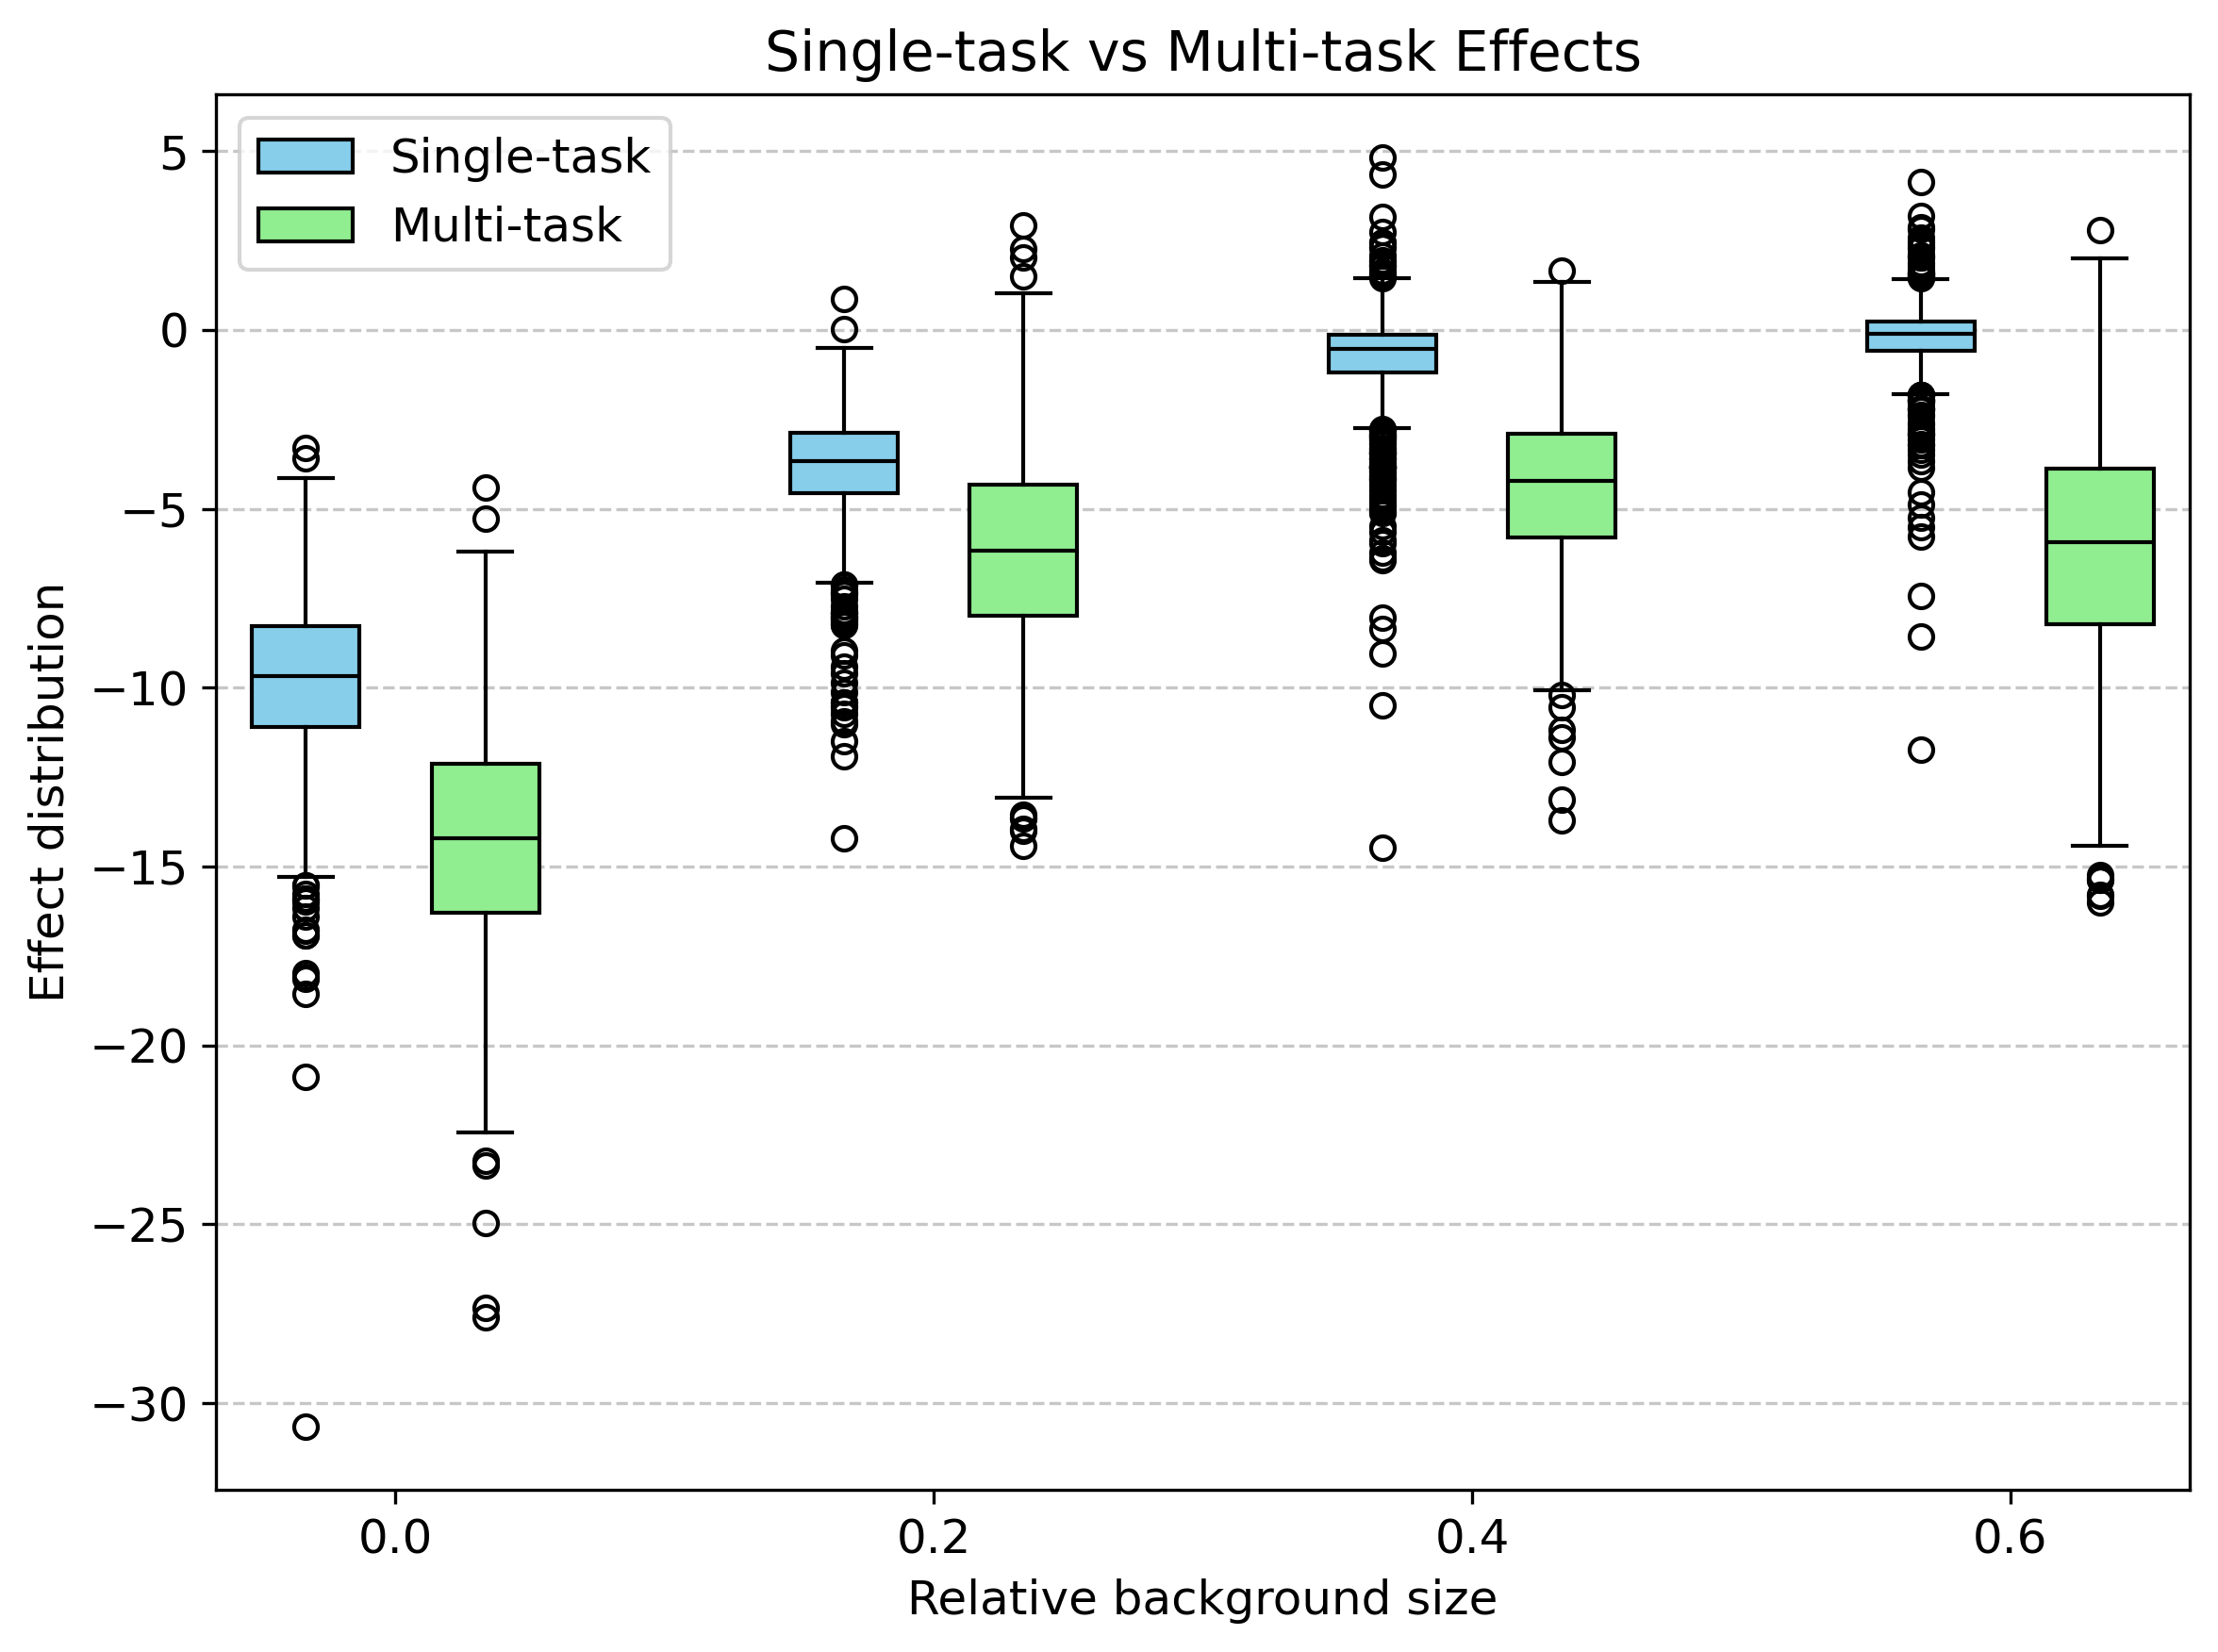

In [13]:

keys = sorted(experiments_single_task.keys())
single_vals = [experiments_single_task[k] for k in keys]
multi_vals = [effects_multitask[k] for k in keys]

plt.figure(figsize=(8,6))
positions = np.arange(len(keys)) * 3

# Single-task boxplots (left)
bp1 = plt.boxplot(single_vals, positions=positions-0.5, widths=0.6,
                  patch_artist=True,
                  boxprops=dict(facecolor="skyblue", color="black"),
                  medianprops=dict(color="black"))

# Multi-task boxplots (right)
bp2 = plt.boxplot(multi_vals, positions=positions+0.5, widths=0.6,
                  patch_artist=True,
                  boxprops=dict(facecolor="lightgreen", color="black"),
                  medianprops=dict(color="black"))

plt.xticks(positions, [str(k) for k in keys])
plt.xlabel("Relative background size", fontsize=12)
plt.ylabel("Effect distribution", fontsize=12)
plt.title("Single-task vs Multi-task Effects", fontsize=14)
plt.legend([bp1["boxes"][0], bp2["boxes"][0]],
           ["Single-task", "Multi-task"],
           loc="best")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()


In [14]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt

# --- Make Illustrator keep text editable ---
mpl.rcParams["pdf.fonttype"] = 42   # embed TrueType (Type 42), NOT Type 3
mpl.rcParams["ps.fonttype"]  = 42
mpl.rcParams["text.usetex"]  = False
mpl.rcParams["font.family"]  = "DejaVu Sans"  # or "Helvetica"/"Arial" if available

# --- Build tidy df (same as before) ---
keys = sorted(experiments_single_task.keys())
single_vals = [np.asarray(experiments_single_task[k]) for k in keys]
multi_vals  = [np.asarray(effects_multitask[k])       for k in keys]

df_single = pd.DataFrame({"key": np.repeat(keys, [len(v) for v in single_vals]),
                          "value": np.concatenate(single_vals),
                          "model": "Single-task"})
df_multi  = pd.DataFrame({"key": np.repeat(keys, [len(v) for v in multi_vals]),
                          "value": np.concatenate(multi_vals),
                          "model": "Multi-task"})
df = pd.concat([df_single, df_multi], ignore_index=True)

# --- Plot split violins ---
plt.figure(figsize=(10, 6))
ax = sns.violinplot(
    data=df, x="key", y="value", hue="model",
    split=True, inner="quartile", cut=0, scale="width",
    order=[str(k) for k in keys],
    palette={"Single-task": "skyblue", "Multi-task": "lightgreen"},
    linewidth=1,
)

ax.set_xlabel("Relative background size", fontsize=12)
ax.set_ylabel("Effect distribution", fontsize=12)
ax.set_title("Single-task vs Multi-task Effects", fontsize=14)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(title="", loc="best")

plt.tight_layout()
# --- Save as PDF with editable text for Illustrator ---
plt.savefig("single_vs_multi_split_violin.pdf",
            format="pdf", bbox_inches="tight", transparent=True)
plt.close()


/tmp/ipykernel_1647563/2176551525.py:28: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


In [30]:
from scipy.stats import mannwhitneyu
import statsmodels.stats.multitest as smm

pvals = []
for k, s_vals, m_vals in zip(keys, single_vals, multi_vals):
    stat, p = mannwhitneyu(s_vals, m_vals, alternative="two-sided")
    pvals.append(p)

# FDR correction
reject, pvals_corrected, _, _ = smm.multipletests(pvals, alpha=0.05, method="fdr_bh")

for k, p, pc, r in zip(keys, pvals, pvals_corrected, reject):
    print(f"{k}: raw p={p:.3e}, adj p={pc:.3e}, significant={r}")


0.0: raw p=1.860e-192, adj p=2.480e-192, significant=True
0.2: raw p=1.307e-99, adj p=1.307e-99, significant=True
0.4: raw p=2.623e-248, adj p=5.246e-248, significant=True
0.6: raw p=9.374e-284, adj p=3.750e-283, significant=True


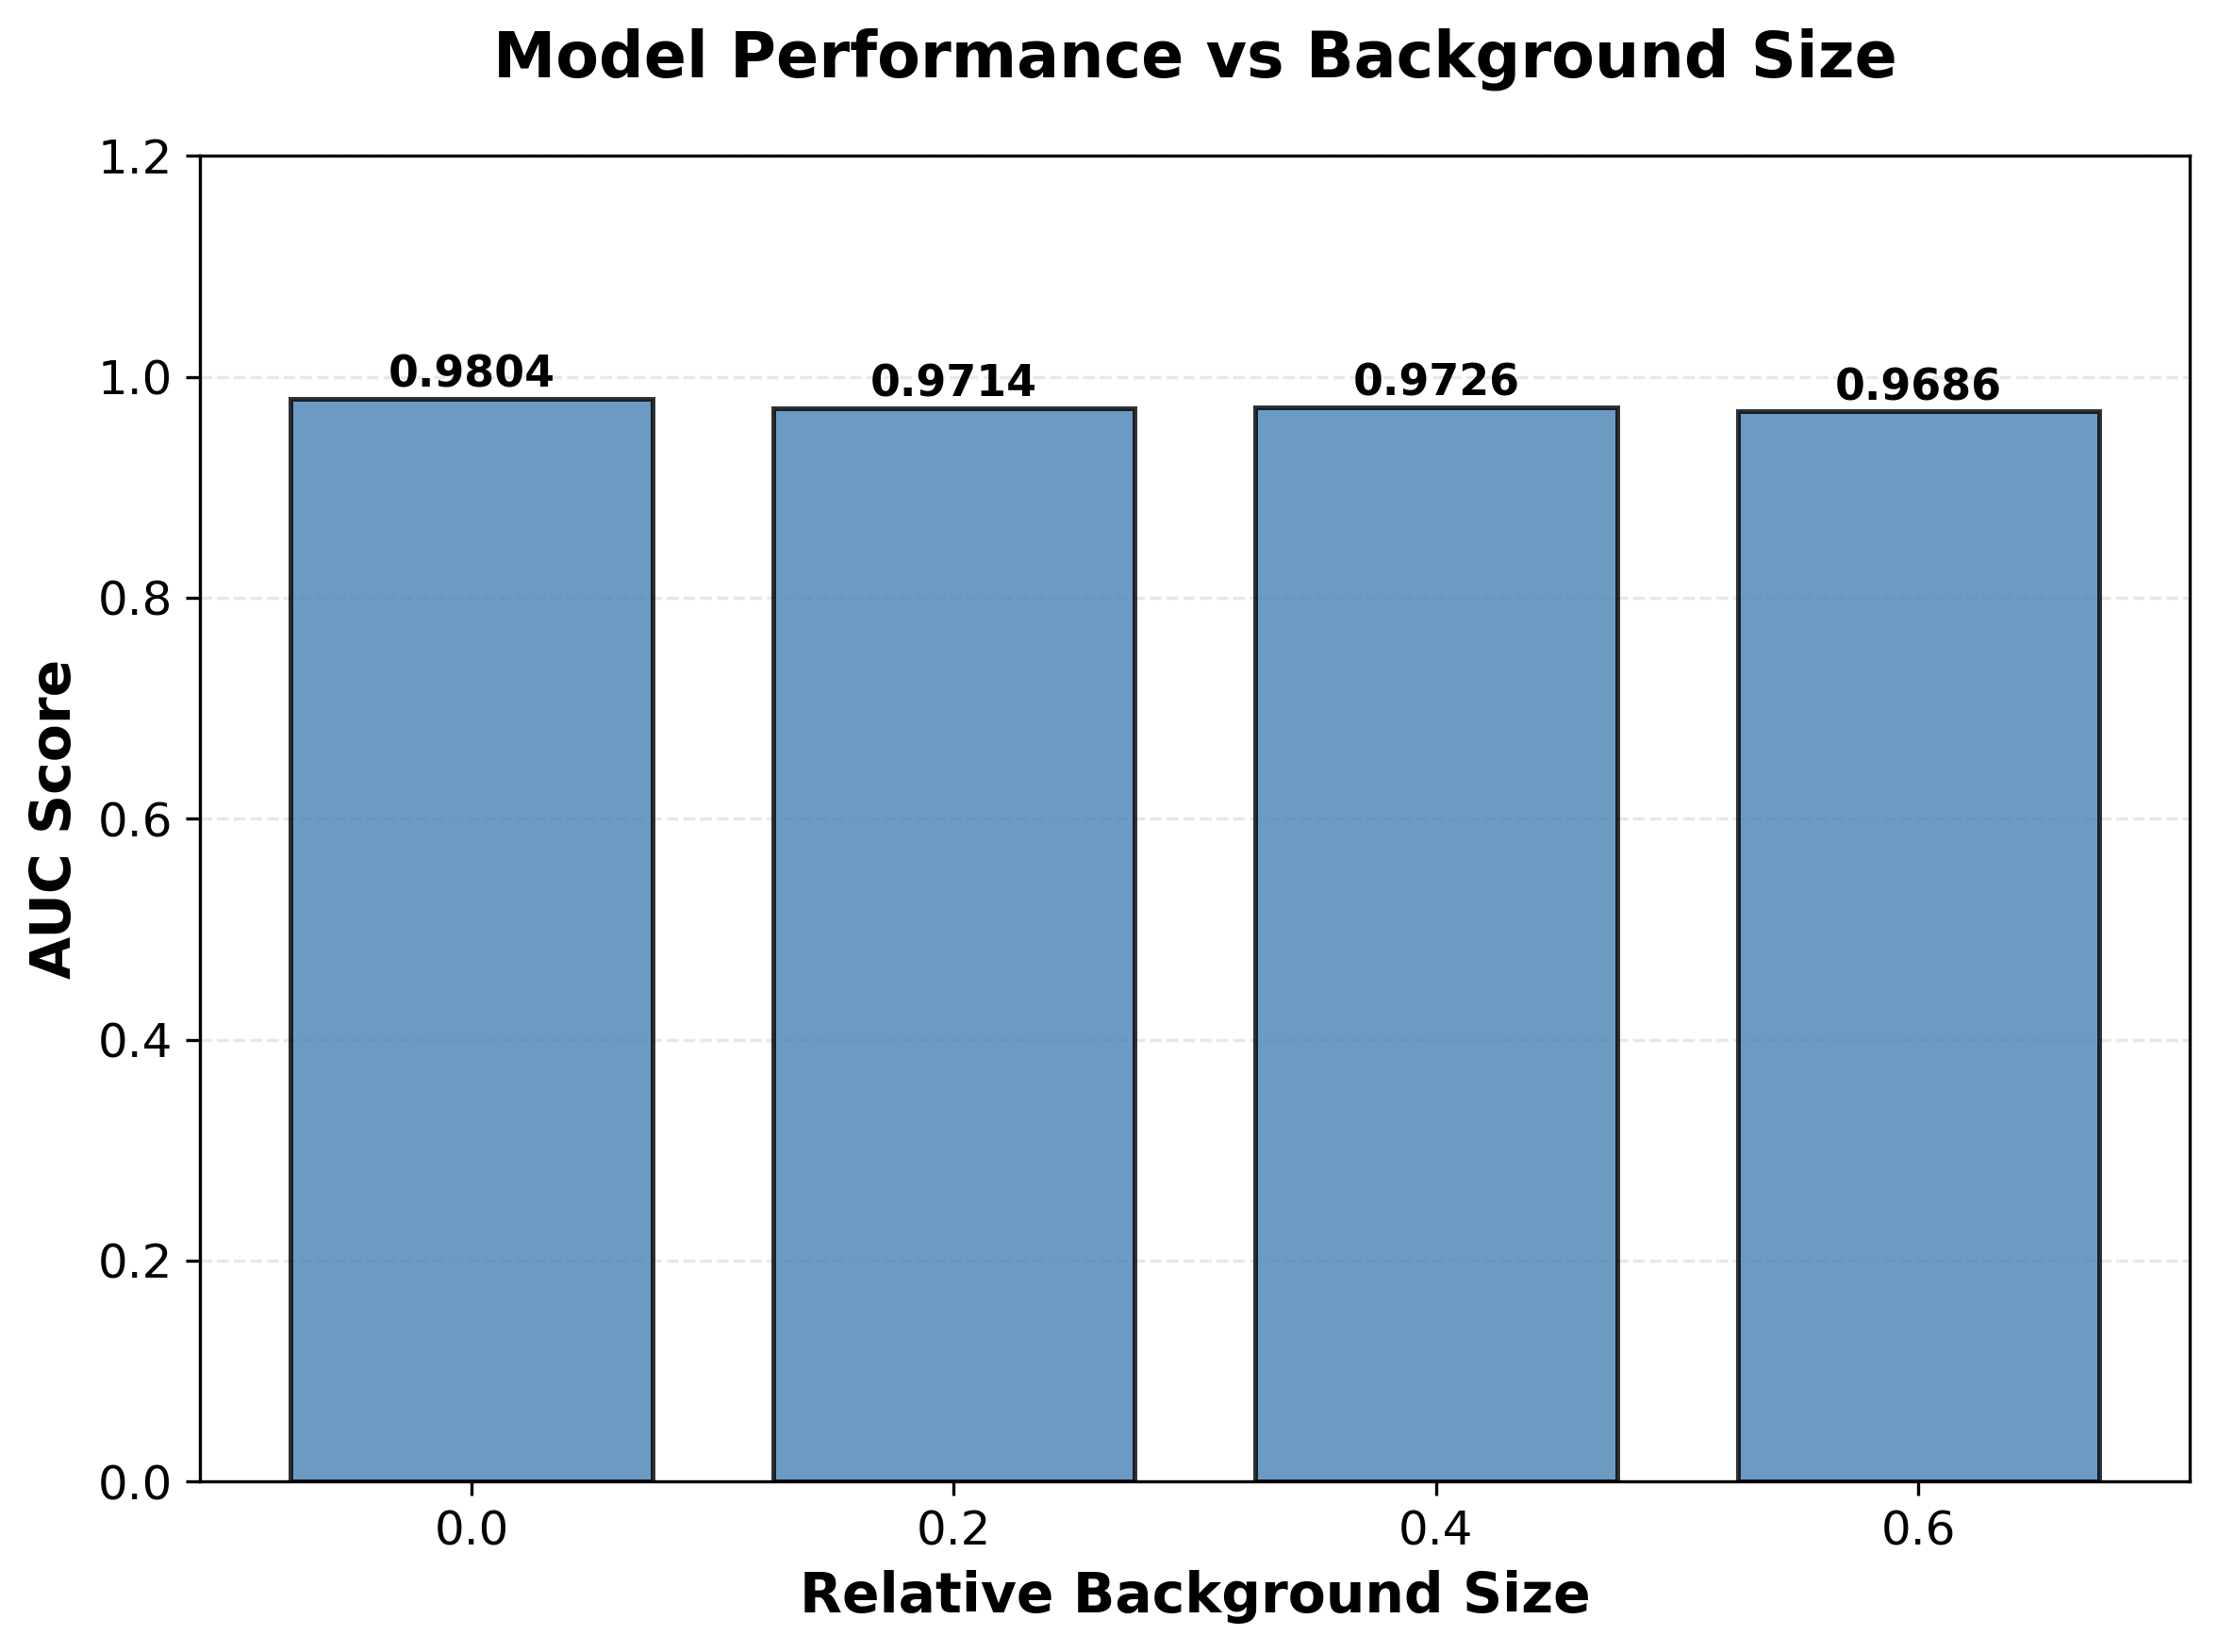

Bar plot saved as 'auc_barplot.pdf'


In [37]:
import matplotlib.pyplot as plt
import numpy as np

# Your dictionary
data_dict = single_task_auc

# Extract keys and values
x_values = list(data_dict.keys())
y_values = list(data_dict.values())

# Create figure with publication-ready settings
fig, ax = plt.subplots(figsize=(8, 6))

# Create bar plot
bars = ax.bar(x_values, y_values, 
              width=0.15,  # Narrower bars for cleaner look
              color='steelblue', 
              edgecolor='black', 
              linewidth=1.2,
              alpha=0.8)

# Customize the plot
ax.set_xlabel('Relative Background Size', fontsize=14, fontweight='bold')
ax.set_ylabel('AUC Score', fontsize=14, fontweight='bold')
ax.set_title('Model Performance vs Background Size', fontsize=16, fontweight='bold', pad=20)

# Set y-axis limits to better show differences
y_min = min(y_values) - 0.01
y_max = max(y_values) + 0.01
ax.set_ylim(0, 1.2)

# Add value labels on top of bars
for bar, value in zip(bars, y_values):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.002,
            f'{value:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Customize grid
ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_axisbelow(True)

# Set x-axis ticks
ax.set_xticks(x_values)
ax.set_xticklabels([f'{x:.1f}' for x in x_values])

# Improve layout
plt.tight_layout()

# Save as PDF
plt.savefig('single_task_auc_barplot.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

# Display the plot
plt.show()

print("Bar plot saved as 'auc_barplot.pdf'")

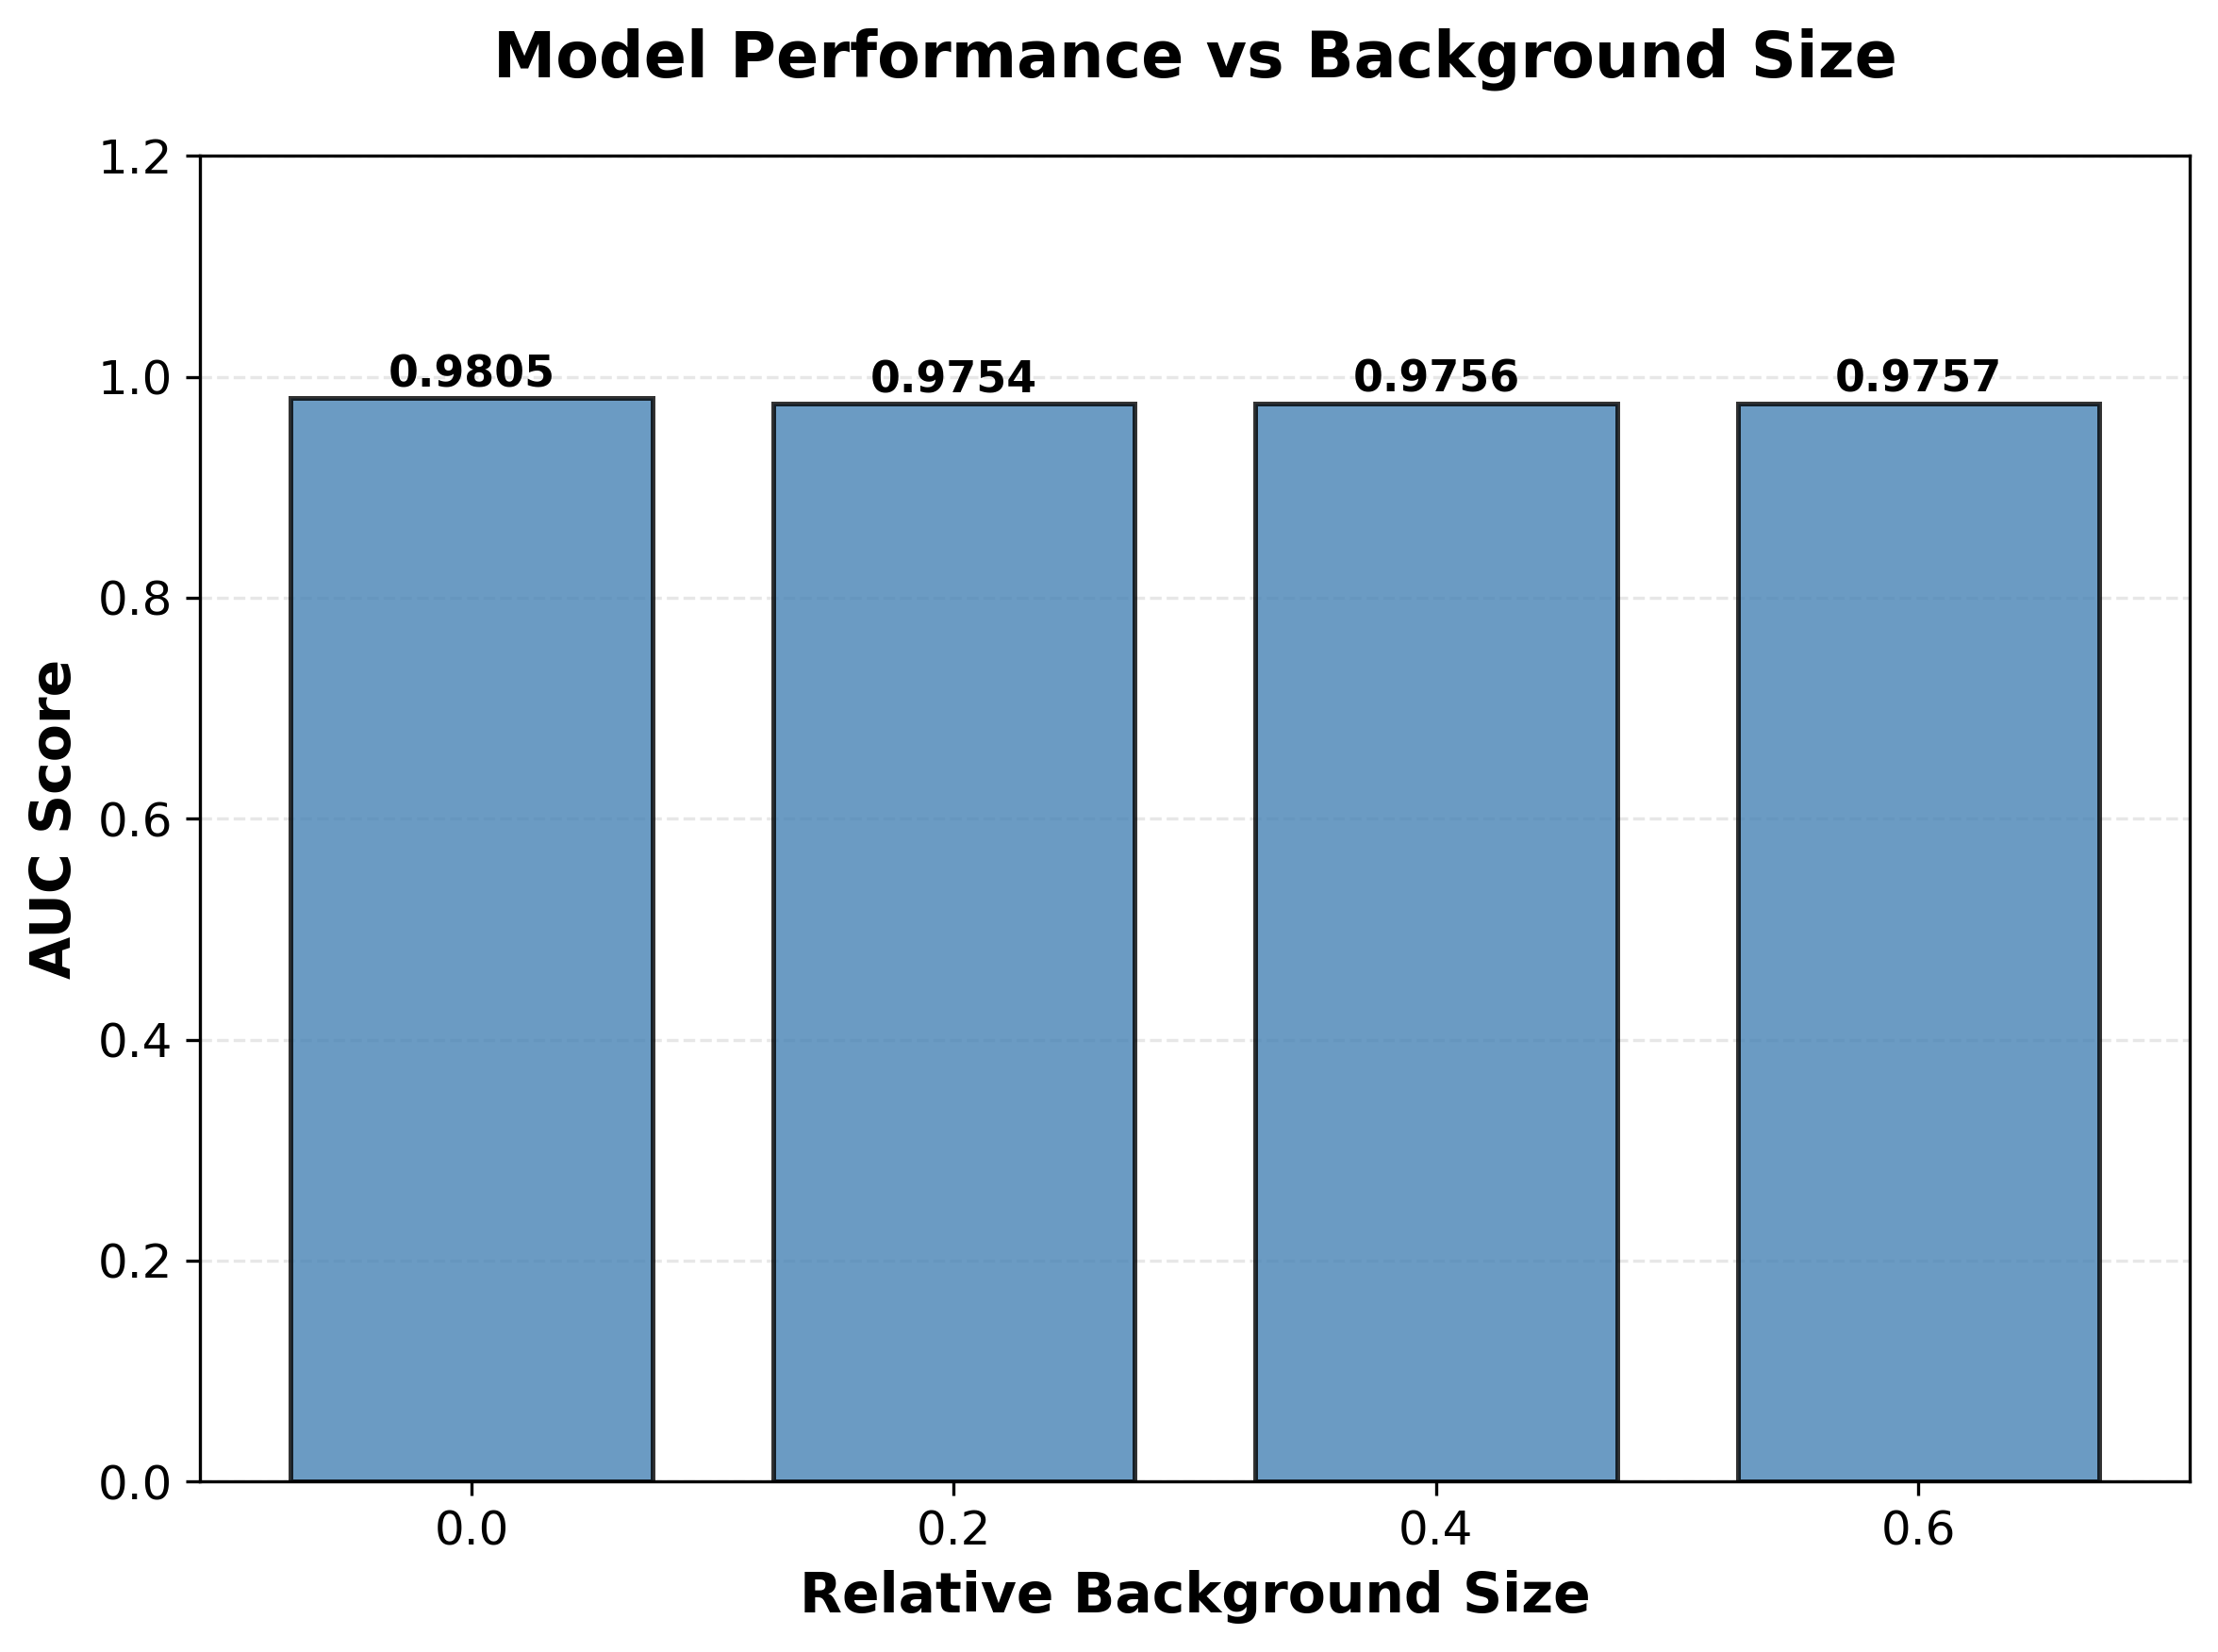

Bar plot saved as 'auc_barplot.pdf'


In [38]:
import matplotlib.pyplot as plt
import numpy as np

# Your dictionary
data_dict = multitask_auc 

# Extract keys and values
x_values = list(data_dict.keys())
y_values = list(data_dict.values())

# Create figure with publication-ready settings
fig, ax = plt.subplots(figsize=(8, 6))

# Create bar plot
bars = ax.bar(x_values, y_values, 
              width=0.15,  # Narrower bars for cleaner look
              color='steelblue', 
              edgecolor='black', 
              linewidth=1.2,
              alpha=0.8)

# Customize the plot
ax.set_xlabel('Relative Background Size', fontsize=14, fontweight='bold')
ax.set_ylabel('AUC Score', fontsize=14, fontweight='bold')
ax.set_title('Model Performance vs Background Size', fontsize=16, fontweight='bold', pad=20)

# Set y-axis limits to better show differences
y_min = min(y_values) - 0.01
y_max = max(y_values) + 0.01
ax.set_ylim(0, 1.2)

# Add value labels on top of bars
for bar, value in zip(bars, y_values):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.002,
            f'{value:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Customize grid
ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_axisbelow(True)

# Set x-axis ticks
ax.set_xticks(x_values)
ax.set_xticklabels([f'{x:.1f}' for x in x_values])

# Improve layout
plt.tight_layout()

# Save as PDF
plt.savefig('multi_task_auc_barplot.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

# Display the plot
plt.show()

print("Bar plot saved as 'auc_barplot.pdf'")

In [157]:
model, auc = train_multitask_model(
    peak_regions=fibro_ipsc_peaks, 
    labels=labels,
    background_regions=background,
    genome_path=hg38,
    relative_proportion=0.0
)

Loading Loci: 100%|██████████| 40931/40931 [00:02<00:00, 20190.58it/s]
/users/kobbad/feat_leakage/fibr_ipsc_peaks_v2/helpers_4.py:114: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loci = torch.tensor(loci, dtype=torch.float32)


Before training - Test Loss: 0.7012
Epoch [1/5]  Train: 0.3341  Val: 0.2104
Epoch [2/5]  Train: 0.1817  Val: 0.1560
Epoch [3/5]  Train: 0.1122  Val: 0.1262
Epoch [4/5]  Train: 0.0763  Val: 0.0999
Epoch [5/5]  Train: 0.0565  Val: 0.0923
After training - Test Loss: 0.1021


In [55]:
from tangermeme.predict import predict

x = predict(model, ohe)

In [56]:
x.shape

torch.Size([1, 2])

In [47]:
joint_peaks = fibro_ipsc_peaks[labels.sum(axis=1) == 2]
two_motifs_loci = extract_loci(joint_peaks, hg38, in_window=300, verbose=True)

Loading Loci: 100%|██████████| 276/276 [00:00<00:00, 3609.71it/s]


In [121]:
joint_peaks.reset_index(drop=True, inplace=True)

In [124]:
chrom, start, end, _ = joint_peaks.iloc[35]

100%|██████████| 38/38 [00:00<00:00, 1276.80it/s]


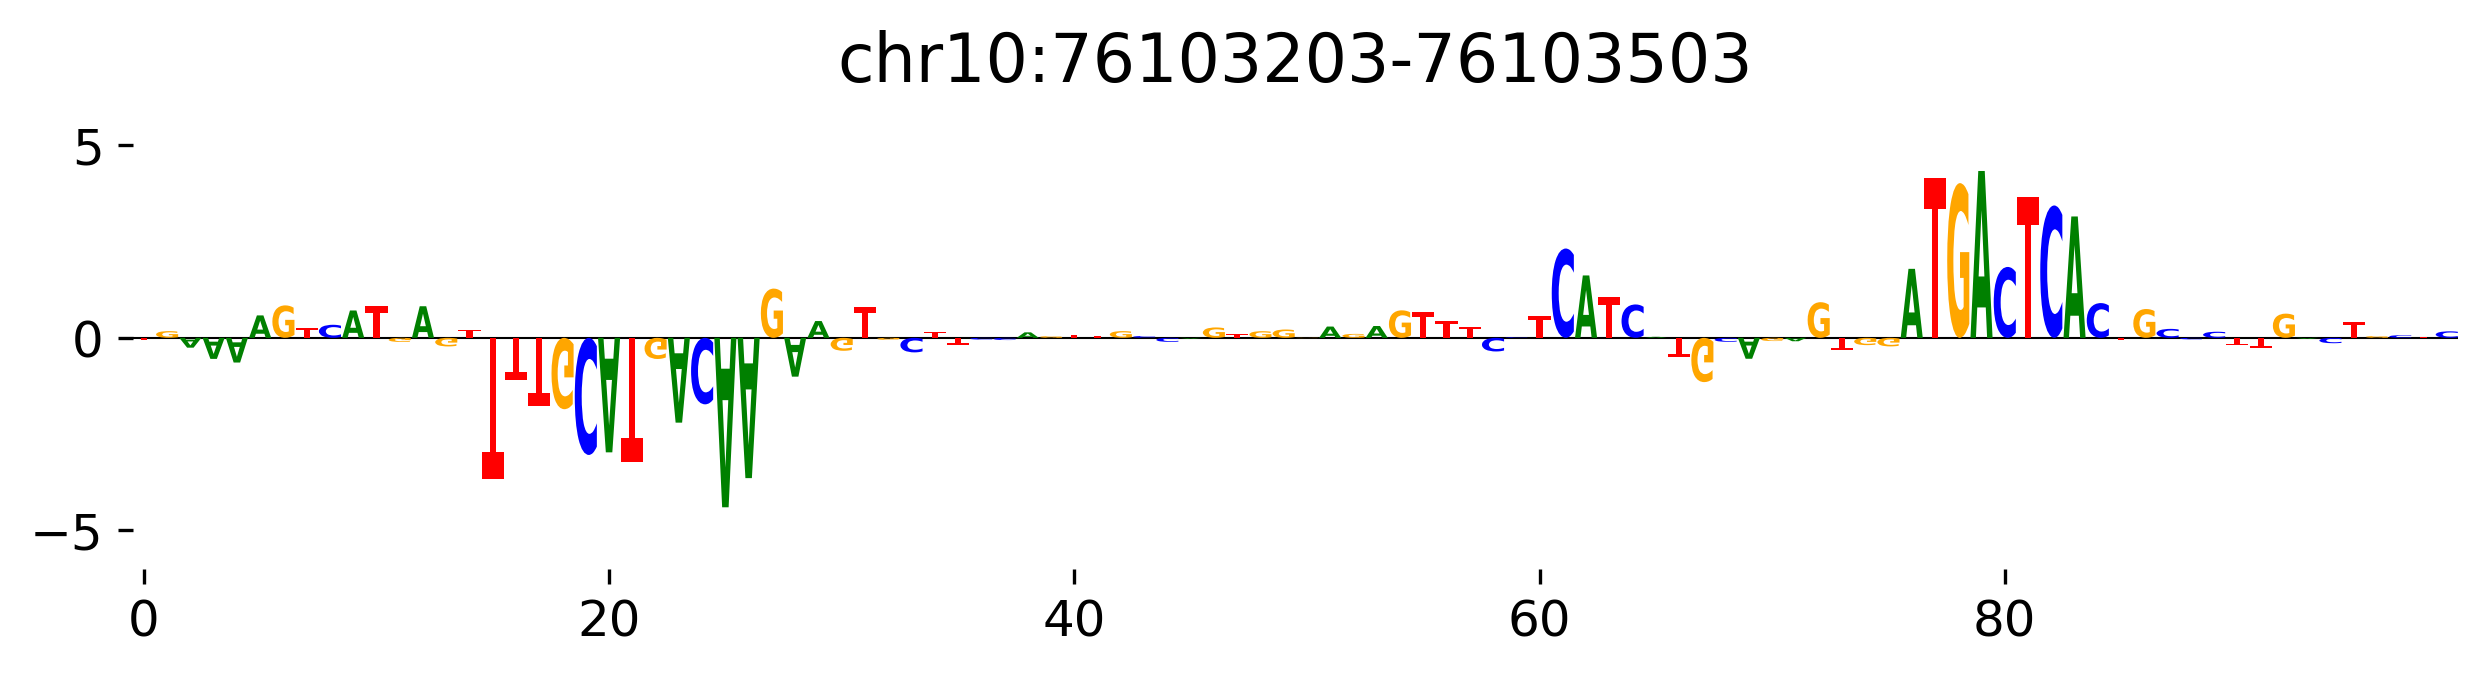

Plot saved as 'saturation_mutagenesis_logo.pdf'


In [158]:
# 16, 28
ohe = two_motifs_loci[35].type(torch.float32).unsqueeze(0)
X_attr = saturation_mutagenesis(model, ohe, target=0, verbose=True)

plt.figure(figsize=(10, 2))
ax = plt.subplot(111)
plot_logo(X_attr[0, :, 120:220], ax=ax)
ax.set_title(f"{chrom}:{start}-{end}")
ax.set_ylim(-6, 6)
# Save as PDF
plt.savefig('saturation_mutagenesis_logo_fibro_head_multitask.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

# Display the plot
plt.show()

print("Plot saved as 'saturation_mutagenesis_logo.pdf'")

100%|██████████| 38/38 [00:00<00:00, 1163.79it/s]


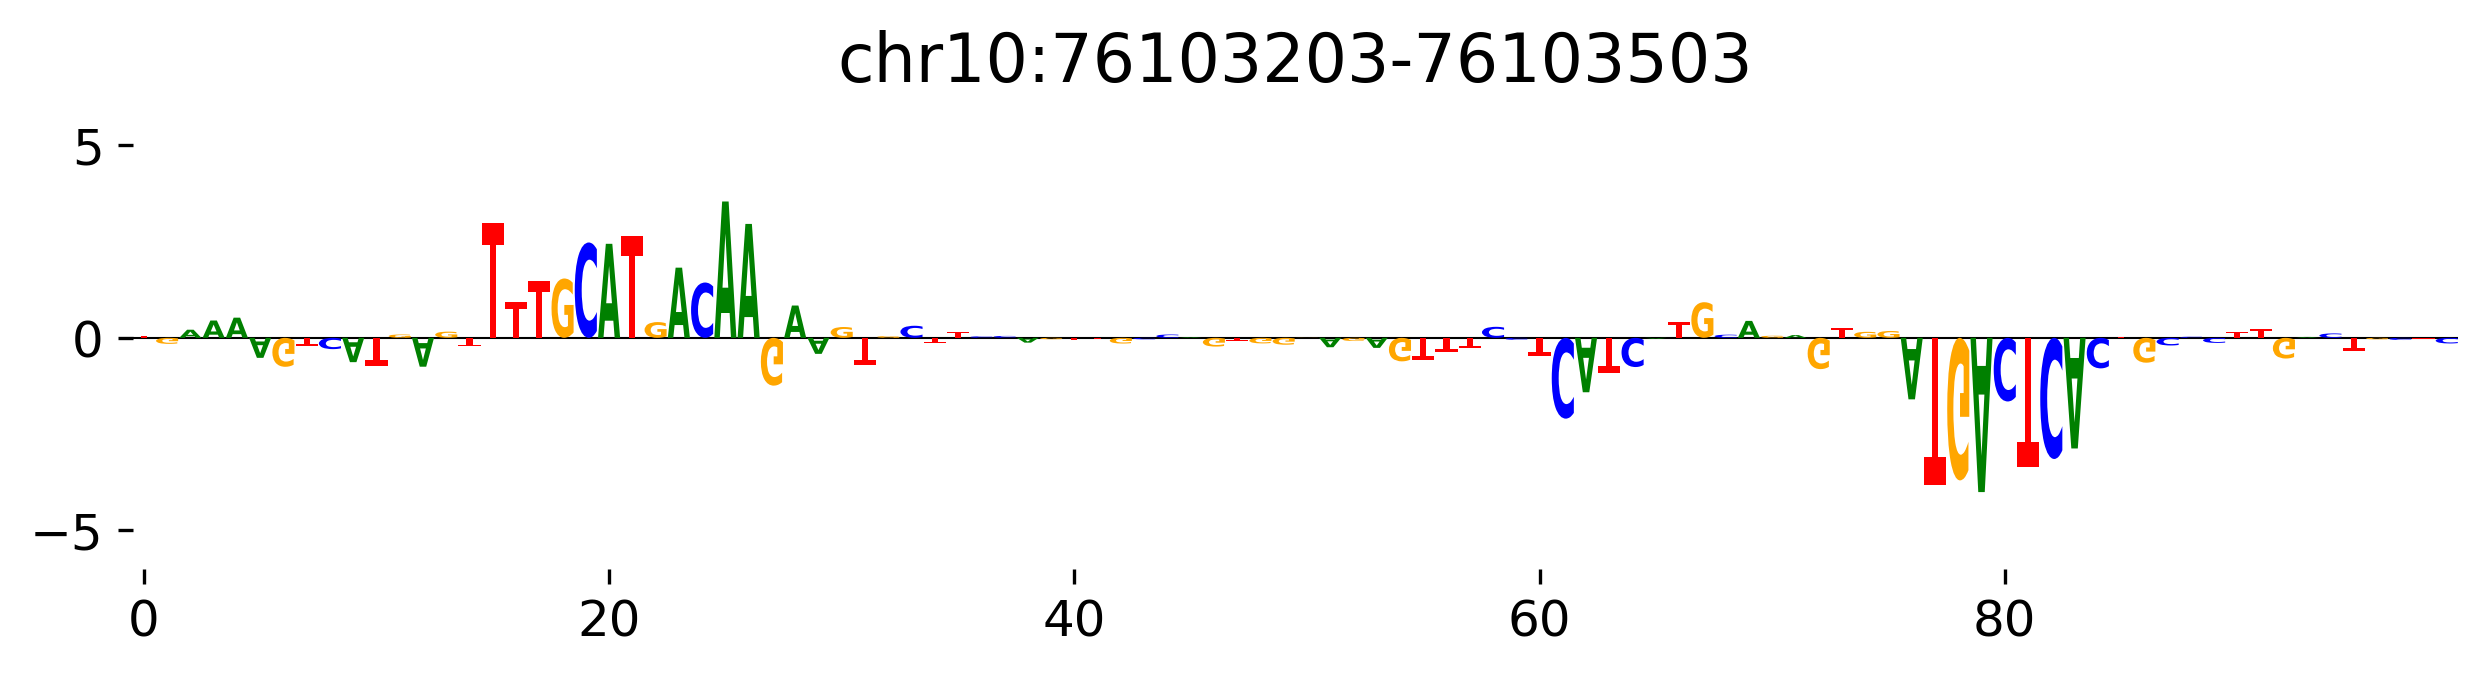

Plot saved as 'saturation_mutagenesis_logo.pdf'


In [159]:
ohe = two_motifs_loci[35].type(torch.float32).unsqueeze(0)
X_attr = saturation_mutagenesis(model, ohe, target=1, verbose=True)

plt.figure(figsize=(10, 2))
ax = plt.subplot(111)
plot_logo(X_attr[0, :, 120:220], ax=ax)
ax.set_title(f"{chrom}:{start}-{end}")
ax.set_ylim(-6, 6)
# Save as PDF
plt.savefig('saturation_mutagenesis_logo_esc_head_multitask.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

# Display the plot
plt.show()

print("Plot saved as 'saturation_mutagenesis_logo.pdf'")

In [128]:
oct4_esc_plus = "/oak/stanford/groups/akundaje/vir/tfatlas/processed_data/ENCSR000BMU/ENCSR000BMU_plus.bigWig"
oct4_esc_minus = "/oak/stanford/groups/akundaje/vir/tfatlas/processed_data/ENCSR000BMU/ENCSR000BMU_minus.bigWig"

two_motifs_loci_plus = extract_loci(joint_peaks, hg38, [oct4_esc_plus],in_window=300, verbose=True)
two_motifs_loci_minus = extract_loci(joint_peaks, hg38, [oct4_esc_minus],in_window=300, verbose=True)

Loading Loci: 100%|██████████| 276/276 [00:01<00:00, 265.95it/s]


In [ ]:
plt.plot(two_motifs_loci_plus[1][35].squeeze().numpy()[350:650] + two_motifs_loci_minus[1][35].squeeze().numpy()[350:650]);

In [142]:
fibro_peaks_plus = "/oak/stanford/groups/akundaje/vir/tfatlas/processed_data/ENCSR124AIG/ENCSR124AIG_plus.bigWig"
fibro_peaks_minus = "/oak/stanford/groups/akundaje/vir/tfatlas/processed_data/ENCSR124AIG/ENCSR124AIG_minus.bigWig"

two_motifs_loci_plus = extract_loci(joint_peaks, hg38, [fibro_peaks_plus],in_window=300, verbose=True)
two_motifs_loci_minus = extract_loci(joint_peaks, hg38, [fibro_peaks_minus],in_window=300, verbose=True)

Loading Loci: 100%|██████████| 276/276 [00:01<00:00, 236.32it/s]


In [ ]:
plt.plot(two_motifs_loci_plus[1][35].squeeze().numpy()[350:650] + two_motifs_loci_minus[1][35].squeeze().numpy()[350:650]);

In [149]:
mask = labels[:,0] == 1

labels_fibroblast = labels[mask]
fibro_ipsc_peaks_fibroblast = fibro_ipsc_peaks[mask]

In [160]:
experiments_single_task = {}
single_task_auc = {}

relative_proportion = 0.1

model, auc = train_singletask_model(
    peak_regions=fibro_ipsc_peaks_fibroblast,
    labels=labels_fibroblast,  # Still pass the full (N, 2) labels array
    background_regions=background,
    genome_path=hg38,
    task_idx=0,  # Choose which task (0=fibroblast, 1=ESC)
    relative_proportion=relative_proportion,
    epochs=5,
    device='cuda'
)
single_task_auc[relative_proportion] = auc

# Test motif effect  
OCT_SOX_MOTIF = "ATTGTTATGCAAAT"
motif_effects = test_motif_effect_singletask(
    model=model,
    test_loci=background_loci,
    motif=OCT_SOX_MOTIF,
    device='cuda'
)

experiments_single_task[relative_proportion] = motif_effects

Loading Loci: 100%|██████████| 39818/39818 [00:02<00:00, 15068.19it/s]
/users/kobbad/feat_leakage/fibr_ipsc_peaks_v2/helpers_4.py:248: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  


Before training - Test Loss: 0.6627
Epoch [1/5]  Train: 0.2934  Val: 0.2109
Epoch [2/5]  Train: 0.1591  Val: 0.1448
Epoch [3/5]  Train: 0.1293  Val: 0.1334
Epoch [4/5]  Train: 0.1041  Val: 0.1384
Epoch [5/5]  Train: 0.0810  Val: 0.1864
After training - Test Loss: 0.1977


100%|██████████| 32/32 [00:00<00:00, 1306.74it/s]


100%|██████████| 38/38 [00:00<00:00, 1293.05it/s]


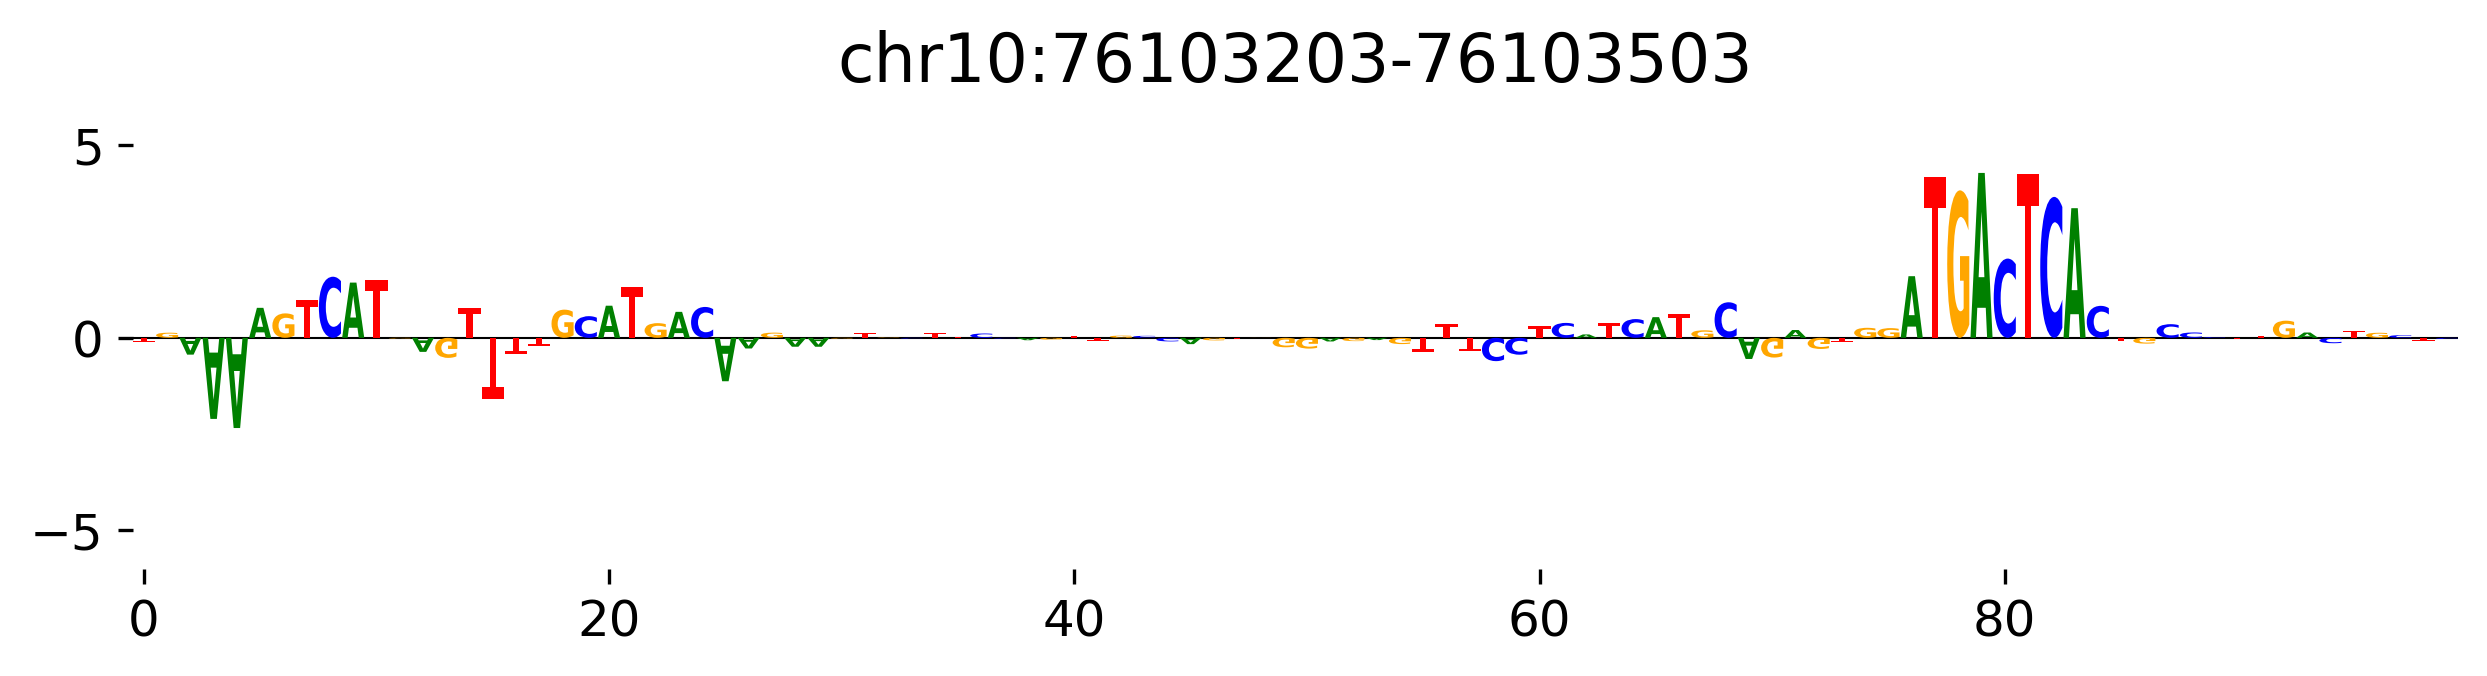

Plot saved as 'saturation_mutagenesis_logo.pdf'


In [161]:
# 16, 28
ohe = two_motifs_loci[35].type(torch.float32).unsqueeze(0)
X_attr = saturation_mutagenesis(model, ohe, target=0, verbose=True)

plt.figure(figsize=(10, 2))
ax = plt.subplot(111)
plot_logo(X_attr[0, :, 120:220], ax=ax)
ax.set_title(f"{chrom}:{start}-{end}")
ax.set_ylim(-6, 6)
# Save as PDF
plt.savefig('saturation_mutagenesis_logo_fibro_head_single_task.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

# Display the plot
plt.show()

print("Plot saved as 'saturation_mutagenesis_logo.pdf'")